In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm

from movebench.study import Study
from movebench.ssf import grouped_nll, SSFDataset, iSSFDataset

In [3]:
# Load a study
study = Study.load('5a280544-06db-4c85-9713-842547972edd')
print(study)

Study('5a280544-06db-4c85-9713-842547972edd')


In [4]:
# Create chip dataset to verify normalization stats exist
train_ds = study.chip_dataset(split='train')
print(f"Train dataset: {len(train_ds)} samples")

# Load one sample
x, mask, transform, crs = train_ds[0]
print(f"Sample shape: {x.shape}")

Train dataset: 1521 samples
Sample shape: torch.Size([72, 79, 77])


In [5]:
# Check validity ratio
print(f"Valid pixel ratio: {len(x[mask]) / len(x.flatten()):.2%}")

Valid pixel ratio: 83.49%


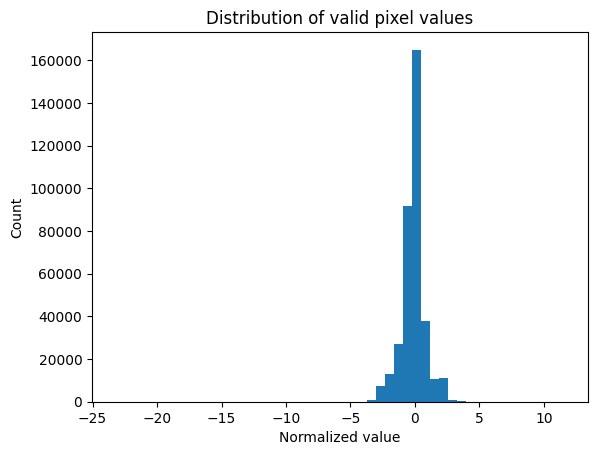

In [6]:
import matplotlib.pyplot as plt

plt.hist(x[mask].numpy(), bins=50)
plt.xlabel('Normalized value')
plt.ylabel('Count')
plt.title('Distribution of valid pixel values')
plt.show()

In [7]:
# Inspect the per-layer normalization stats
import json

stats_file = study._study_dir / "normalization" / "stats.json"
with open(stats_file) as f:
    stats = json.load(f)

print(f"Normalization stats stored in: {stats_file}")
print(f"Layers with stats: {list(stats.keys())}")
print(f"\nExample - era5_land bands:")
for band, vals in list(stats.get('era5_land', {}).get('bands', {}).items())[:3]:
    print(f"  {band}: mean={vals['mean']:.4f}, std={vals['std']:.4f}")

Normalization stats stored in: /data/vision/beery/scratch/justin/movebench/studies/5a280544-06db-4c85-9713-842547972edd/normalization/stats.json
Layers with stats: ['modis_lst', 'modis_vi', 'modis_ndsi', 'modis_bai', 'era5_land', 'era5', 'dem', 'modis_cvf_tree', 'modis_cvf_nontree', 'modis_cvf_nonveg', 'hii', 'bioclim', 'dynamic_world']

Example - era5_land bands:
  temperature_2m: mean=272.9991, std=5.4522
  dewpoint_temperature_2m: mean=269.1833, std=5.0397
  total_precipitation: mean=0.0004, std=0.0011


## Create SSF Dataset (New Optimized Implementation)

The new `SSFDataset` from `movebench.ssf` is used automatically via `study.ssf_dataset()`. Key improvements:
- Faster extraction (especially for test data with 15x buffer)
- Correct nodata handling (no garbage values from interpolation)

In [8]:
# Create SSF dataset using the new optimized implementation
# study.ssf_dataset() now uses movebench.ssf.SSFDataset internally
ssf_ds = study.ssf_dataset(split='train')
print(f"SSF dataset: {len(ssf_ds)} samples")
print(f"Implementation: {type(ssf_ds).__module__}.{type(ssf_ds).__name__}")

# Load one sample: (C, num_candidates+1) where C=72 channels, 100 pseudo + 1 true endpoint
step_pixels, valid_pixels, transform, crs = ssf_ds[0]
print(f"Step pixels shape: {step_pixels.shape}")

SSF dataset: 1513 samples
Implementation: movebench.ssf.SSFDataset


/data/vision/beery/scratch/justin/movebench/movebench/utils.py:181: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df['valid_step'].shift(-1).fillna(False).astype(bool)


Step pixels shape: torch.Size([72, 101])


In [9]:
# Inspect features for the first candidate
print("Features for first candidate point:")
print(step_pixels[:, 0])
print("\nValid mask:")
print(valid_pixels[:, 0])

Features for first candidate point:
tensor([-1.3237e+00, -2.6514e+00, -8.3305e-01, -8.9066e-01,  4.9868e-01,
        -2.6754e-01, -5.0071e+01, -5.3413e+01, -3.1786e-01, -1.2161e+02,
         1.4123e-01,  1.6252e-01, -7.7303e-01, -1.6405e+00, -7.0903e-01,
         1.3400e+00,  6.8553e-01,  2.8287e-01, -8.1358e-01,  1.4478e-01,
         2.0345e+00, -8.0913e-01,  0.0000e+00,  0.0000e+00,  0.0000e+00,
         0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00,
         0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
         0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
        -1.9295e-01,  8.9413e-01, -1.2026e+00,  1.7482e-01, -6.7222e-01,
         2.3302e-01,  1.1147e+00, -1.1317e+00, -1.0903e+00,  2.4404e-01,
        -1.0907e+00, -1.3143e+00,  1.9922e-01, -1.1246e+00,  6.2270e-01,
         9.5697e-01,  2.8730e-01, -2.5790e-01, -4.7831e-01,  8.2300e-01,
         5.7571e-01,  6.4213e-01,  3.5788e-01, -1.8730e-01, -3.7662e-01,
        -3.8941

In [10]:
# Verify no garbage values (the old implementation could produce values like -9409 for HII)
from movebench.config import get_channel_indices

indices = get_channel_indices()
hii_start, hii_end = indices['hii']

hii_vals = step_pixels[hii_start:hii_end]
hii_valid = valid_pixels[hii_start:hii_end]

valid_hii = hii_vals[hii_valid]
print(f"HII values (valid range ~0-64):")
print(f"  Min: {valid_hii.min().item():.2f}")
print(f"  Max: {valid_hii.max().item():.2f}")
print(f"  No garbage values: {valid_hii.min().item() > -100}")

HII values (valid range ~0-64):
  Min: -0.41
  Max: 1.47
  No garbage values: True


---
## Train SSF Model

Train a conditional logistic regression model directly using the SSFDataset.

In [ ]:
# Extract features from SSFDataset

def extract_ssf_features(dataset, num_workers=8):
    """Extract all features from an SSFDataset into tensors."""
    loader = DataLoader(dataset, batch_size=1, shuffle=False, num_workers=num_workers)
    
    all_xs = []
    all_masks = []
    
    for step_pixels, valid_pixels, _, _ in tqdm(loader, desc="Extracting features"):
        all_xs.append(step_pixels)
        all_masks.append(valid_pixels)
    
    # Stack: (N, C, num_candidates+1)
    X = torch.cat(all_xs, dim=0)
    masks = torch.cat(all_masks, dim=0)
    
    # Reshape to (N * (num_candidates+1), C) for regression
    N, C, K = X.shape
    X = X.permute(0, 2, 1).reshape(-1, C)
    masks = masks.permute(0, 2, 1).reshape(-1, C)
    
    # Labels: last candidate (index K-1) is the true endpoint
    y = torch.zeros(N * K, dtype=torch.long)
    y[K-1::K] = 1  # Every K-th element starting from K-1
    
    # Group indices for conditional logistic regression
    starts = torch.arange(0, N * K, K)
    ends = torch.arange(K, N * K + 1, K)
    
    return X, masks, y, starts, ends

# Extract train features (test extraction would be much faster with new impl)
train_ssf = study.ssf_dataset(split='train')

X_tr, masks_tr, y_tr, starts_tr, ends_tr = extract_ssf_features(train_ssf)

print(f"Train features: {X_tr.shape}")
print(f"Train groups: {len(starts_tr)}")

/data/vision/beery/scratch/justin/movebench/movebench/utils.py:181: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df['valid_step'].shift(-1).fillna(False).astype(bool)
Extracting features:   8%|▊         | 115/1513 [00:11<02:10, 10.69it/s]

In [ ]:
# Clean features: fill invalid values with 0 (approx mean after normalization)
def clean_features(X, masks):
    X_clean = torch.where(masks, X, torch.tensor(0.0))
    X_clean = torch.nan_to_num(X_clean, nan=0.0, posinf=0.0, neginf=0.0)
    return X_clean

X_tr_clean = clean_features(X_tr, masks_tr)

print(f"Features per sample: {X_tr_clean.shape[1]}")

In [ ]:
# Train conditional logistic regression
num_features = X_tr_clean.shape[1]
beta = torch.zeros(num_features, dtype=torch.float32, requires_grad=True)
opt = torch.optim.Adam([beta], lr=1e-2, weight_decay=1e-3)

for step in range(1000):
    opt.zero_grad()
    loss = grouped_nll(beta, X_tr_clean, y_tr, starts_tr, ends_tr)
    loss.backward()
    opt.step()
    
    if step % 100 == 0:
        with torch.no_grad():
            nll_tr = grouped_nll(beta, X_tr_clean, y_tr, starts_tr, ends_tr).item()
            print(f"Step {step:4d} | Train NLL: {nll_tr:.4f}")

In [ ]:
# Inspect learned coefficients
from movebench.config import get_channel_indices, LAYERS

print("Top 10 coefficients by magnitude:\n")

# Build channel names from layer config
indices = get_channel_indices()
channel_names = []
for name, (start, end) in indices.items():
    layer = LAYERS[name]
    if layer.categorical:
        for i in range(layer.num_classes):
            channel_names.append(f"{name}_class{i}")
    else:
        for band in layer.bands:
            channel_names.append(f"{name}_{band}")

beta_np = beta.detach().numpy()
sorted_idx = abs(beta_np).argsort()[::-1]

for i in sorted_idx[:10]:
    print(f"{channel_names[i]:40s} {beta_np[i]:+.4f}")

## Test Set Evaluation

The new SSFDataset is especially faster for test data, which uses a 15x spatial buffer.

In [ ]:
import time

# Time test set extraction
test_ssf = study.ssf_dataset(split='test')
print(f"Test dataset: {len(test_ssf)} samples")

start = time.time()
X_te, masks_te, y_te, starts_te, ends_te = extract_ssf_features(test_ssf)
elapsed = time.time() - start

print(f"Test extraction time: {elapsed:.1f}s")
print(f"Test features: {X_te.shape}")

In [ ]:
# Evaluate on test set
X_te_clean = clean_features(X_te, masks_te)

with torch.no_grad():
    nll_te = grouped_nll(beta, X_te_clean, y_te, starts_te, ends_te).item()
    print(f"Test NLL: {nll_te:.4f}")